# InterviewBot - FER2013 Emotion Model (CNN)
**Run order:** upar se neeche, ek ek cell (Shift+Enter).
Pehle GPU chalu karo (Kaggle: Settings > Accelerator > GPU).

## Cell 1: Libraries + GPU check

In [ ]:
# Libraries: numpy = arrays, tensorflow/keras = model, matplotlib = graph, sklearn = report/metrics
import os, json
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (EarlyStopping, ModelCheckpoint,
                                        ReduceLROnPlateau, BackupAndRestore)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

tf.keras.utils.set_random_seed(42)   # har run mein random cheezein same rahein (results compare ho sakein)

gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus)                  # [] matlab GPU nahi mila (CPU par chalega, slow)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Cell 2: Dataset path check (galat path ho to yahin pata chal jayega)

In [ ]:
import zipfile
import os

# Exact path with space handled properly
zip_path = '/content/FER 2013.zip'
extract_path = '/content/fer2013_extracted'

# Folder create karein agar pehle se nahi hai
os.makedirs(extract_path, exist_ok=True)

print("Extracting FER 2013 dataset...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset successfully extract ho gaya hai!")
print("Extracted contents/folders:", os.listdir(extract_path))

Extracting FER 2013 dataset...
✅ Dataset successfully extract ho gaya hai!
Extracted contents/folders: ['test', 'train']


## Cell 3: Data loading

In [ ]:
DATA_DIR = "/content/fer2013_extracted"   # Colab dataset path
IMG, BATCH, SEED = (48, 48), 64, 42       # image size, ek baar mein 64 images, random seed

# Train data: folder ke naam se label khud ban jata hai
train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/train",
    color_mode="grayscale",   # 1 channel (model Input shape (48,48,1) hai)
    image_size=IMG,
    batch_size=BATCH,
    label_mode="int",         # labels 0-6 numbers (sparse loss ke liye zaroori)
    shuffle=True,             # train mein images mix karo
    seed=SEED)

# Validation data: shuffle=False taake baad mein predictions ka order labels se match kare
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/test",
    color_mode="grayscale",
    image_size=IMG,
    batch_size=BATCH,
    label_mode="int",
    shuffle=False)

class_names = train_ds.class_names    # alphabetical order mein 7 emotions
print(class_names)

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.
['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## Cell 4: Class weights (kam images wali class ko zyada weightage)

In [ ]:
# Train ke saare labels ek array mein jama karo
y_train = np.concatenate([y.numpy() for _, y in train_ds])

# "balanced" = kam images wali class ka weight zyada (Disgust ~9x ho jata hai)
w = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=y_train)

# sqrt = weights ko naram karta hai, taake training noisy na ho
class_weights = dict(enumerate(np.sqrt(w)))
print(class_weights)

# Speed: prefetch = agla batch pehle se tayyar rakhta hai, cache = val data RAM mein rakh leta hai
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds   = val_ds.cache().prefetch(tf.data.AUTOTUNE)

{0: np.float64(1.0132150237866404), 1: np.float64(3.067021129817506), 2: np.float64(1.0005228940799697), 3: np.float64(0.7539487836973864), 4: np.float64(0.9088671073312443), 5: np.float64(0.9214811322418858), 6: np.float64(1.1372655707135448)}


## Cell 5: Model banana

In [16]:
# 1. 4th block (512) add kiya taake Fear/Sad/Neutral ka barik farq pakad sake
FILTERS = (64, 128, 256, 512) if gpus else (32, 64, 128, 256)
print("Filters:", FILTERS)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.08),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.1),              # NEW: lighting ka farq handle karne ke liye
], name="augmentation")

def conv_block(x, filters, drop_rate=0.25):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          kernel_initializer="he_normal")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(drop_rate)(x)
    return x

inputs = layers.Input(shape=(48, 48, 1))
x = layers.Rescaling(1./255)(inputs)
x = data_augmentation(x)

for f in FILTERS:
    x = conv_block(x, f)

# 2. GlobalAveragePooling ki jagah Flatten + Dense taake face structure yaad rahe
x = layers.Flatten()(x)
x = layers.Dense(512, use_bias=False, kernel_initializer="he_normal")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = models.Model(inputs, outputs)
model.summary()

# 3. AdamW (weight_decay ke sath) overfitting kam karta hai aur accuracy barhata hai
model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

Filters: (64, 128, 256, 512)


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 48, 48, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 48, 48, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 24, 24, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 12, 12, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 7,054,919 (26.91 MB)

 Trainable params: 7,050,055 (26.89 MB)

 Non-trainable params: 4,864 (19.00 KB)

## Cell 6: Training
- `EPOCHS = 100` rakha hai. Sirf code test karna ho to `EPOCHS = 2` kar do.
- EarlyStopping khud rok dega jab val accuracy 12 epoch tak na badhe.

In [17]:
import shutil
shutil.rmtree("backup_dir", ignore_errors=True)  # ZAROORI: Purane model ka backup delete karega taake error na aaye

EPOCHS = 100

callbacks = [
    BackupAndRestore("backup_dir"),     # crash/disconnect ho to wahin se resume
    EarlyStopping(monitor="val_accuracy", mode="max", patience=15,
                  restore_best_weights=True),            # 15 epoch improve na ho to stop, best weights wapas
    ModelCheckpoint("best_emotion_model.keras", monitor="val_accuracy",
                    mode="max", save_best_only=True),    # sirf best model save
    ReduceLROnPlateau(monitor="val_accuracy", mode="max", factor=0.5, patience=5,
                      min_lr=1e-6, verbose=1),           # 5 epoch accuracy na barhe to learning rate aadha
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weights, callbacks=callbacks)

Epoch 1/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.2725 - loss: 1.9046 - val_accuracy: 0.2919 - val_loss: 1.9432 - learning_rate: 0.0010
Epoch 2/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.3965 - loss: 1.5820 - val_accuracy: 0.3211 - val_loss: 1.8449 - learning_rate: 0.0010
Epoch 3/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.4647 - loss: 1.3957 - val_accuracy: 0.4897 - val_loss: 1.3211 - learning_rate: 0.0010
Epoch 4/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5056 - loss: 1.2895 - val_accuracy: 0.4029 - val_loss: 1.5602 - learning_rate: 0.0010
Epoch 5/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.5231 - loss: 1.2417 - val_accuracy: 0.5130 - val_loss: 1.2796 - learning_rate: 0.0010
Epoch 6/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.5472 - loss: 1.1882 - val_accuracy: 0.5163 - val_loss: 1.2934 - learning_rate: 0.0010
Epoch 7/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5568 - l

## Cell 7: Evaluation (accuracy, per-class report, confusion matrix, graph)

113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6952 - loss: 1.2177
Validation Accuracy: 69.52%
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

       angry       0.60      0.64      0.62       958
     disgust       0.77      0.72      0.74       111
        fear       0.57      0.52      0.55      1024
       happy       0.89      0.87      0.88      1774
     neutral       0.62      0.68      0.65      1233
         sad       0.59      0.55      0.57      1247
    surprise       0.80      0.83      0.82       831

    accuracy                           0.70      7178
   macro avg       0.69      0.69      0.69      7178
weighted avg       0.70      0.70      0.69      7178

[[ 614    9   92   25   88  113   17]
 [  23   80    2    2    1    2    1]
 [ 122    6  535   24   99  160   78]
 [  40    2   33 1544   86   32   37]
 [  83    2   71   70  834  155   18]
 [ 131    5  139   43  215  691   23]
 [  17    0   64   32   16   10

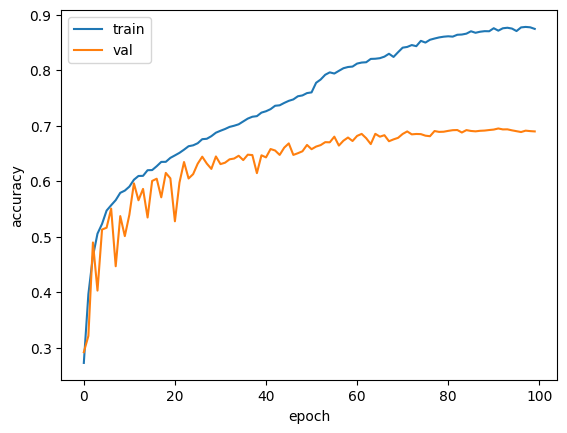

In [19]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"Validation Accuracy: {val_acc*100:.2f}%")

# Asli labels aur model ki predictions (val_ds shuffle=False hai, isliye order match)
y_true = np.concatenate([y.numpy() for _, y in val_ds])
y_pred = np.argmax(model.predict(val_ds), axis=1)

# Har emotion ka precision/recall/f1 (kaun si emotion kamzor hai)
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion matrix: row = asli emotion, column = model ne kya bola
print(confusion_matrix(y_true, y_pred))

# Learning curve (overfitting dekhne ke liye): train aur val accuracy
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.legend(); plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.show()

## Cell 8: Class names save (webcam inference code mein zaroorat paregi)

In [20]:
from google.colab import files

# Model sirf 0-6 number deta hai; number -> emotion naam ke liye ye list chahiye
with open("class_names.json", "w") as f:
    json.dump(class_names, f)
print("Saved:", class_names)

# Colab se dono files seedha apne PC par download karne ke liye:
files.download("best_emotion_model.keras")
files.download("class_names.json")

Saved: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>